<a href="https://colab.research.google.com/github/zivnagad/Bayesian_models/blob/main/Assignment1PyMc_basics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
from arviz import plot_posterior
import pymc as pm
import numpy as np
import matplotlib.pyplot as plt
import pickle as pkl

## Exercise 1: in class we tried to find when and if there was a change in the arrival rate of text massaging per day.
### Suppose you suspect there were actually three different rates (that is, two different witching points).
#### In the next exercise, follow the same line of thought of the model with two different rates and apply it for differetn three different rates.

#### The goal is to understand it there are more than two switching points.

## Instructions:

### 1. Load the data. First upload it to the drive and then mount it into colab.
### 2. Build a pymc model like we did in class. This means choosing priors, likelihood, number of MCMC samples, and constructing determinstic functions with 'switch'.
### 3. Analyzing the posterior. Extracing the posterior samples and visualzing them.

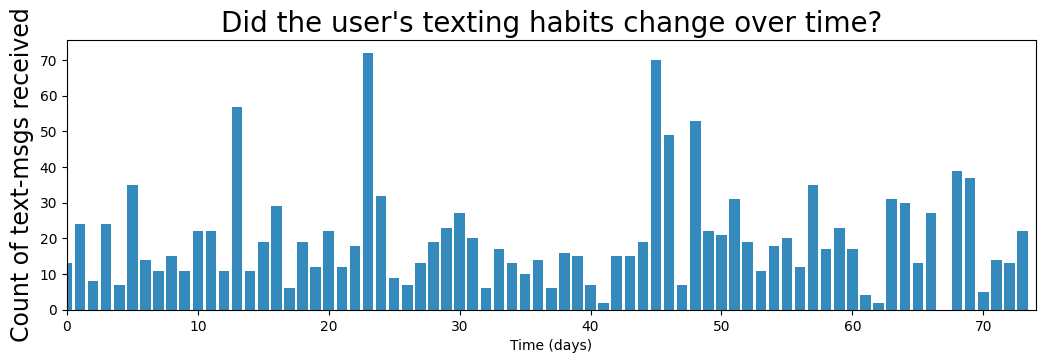

In [5]:
%matplotlib inline
from IPython.core.pylabtools import figsize
figsize(12.5, 3.5)

# from google.colab import drive
# drive.mount('/content/drive')

colab = True #fix to you
if colab:
  count_data = np.loadtxt("/txtdata.csv")
else:
  count_data = np.loadtxt("../data/txtdata.csv")


n_count_data = len(count_data)
plt.bar(np.arange(n_count_data), count_data, color="#348ABD")
plt.xlabel("Time (days)")
plt.ylabel("Count of text-msgs received", fontsize = 17)
plt.title("Did the user's texting habits change over time?", fontsize = 20)
plt.xlim(0, n_count_data);

In [6]:
count_data.shape

(74,)

In [7]:
with pm.Model() as model:
    alpha = 1.0/count_data.mean()

    # Priors: שלושה קצבים ממוצעים, אחד לכל תקופה
    lambdas = pm.Exponential("lambda_priors", alpha, shape=3)

    # Priors: שתי נקודות שינוי. tau_2 תמיד אחרי tau_1
    tau_1 = pm.DiscreteUniform("tau_1", lower=0, upper=n_count_data - 1)
    tau_2 = pm.DiscreteUniform("tau_2", lower=tau_1, upper=n_count_data - 1)

    # Deterministic: הקצב בכל יום לפי התקופה שבה הוא נמצא
    idx = np.arange(n_count_data)
    lambda_ = pm.Deterministic("lambda_", pm.math.switch(idx < tau_1, lambdas[0],
                                          pm.math.switch(idx < tau_2, lambdas[1], lambdas[2])))

    # Likelihood: מספר ההודעות בכל יום מתפלג פואסון עם הקצב של אותו יום
    observation = pm.Poisson("obs", lambda_, observed=count_data)

    # Sampling
    step = pm.Metropolis()
    trace = pm.sample(5000, tune=1000, step=step)

Output()

/usr/local/lib/python3.13/dist-packages/arviz/stats/diagnostics.py:596: RuntimeWarning: invalid value encountered in scalar divide
  (between_chain_variance / within_chain_variance + num_samples - 1) / (num_samples)


In [8]:
lambda_1_samples = trace.posterior['lambda_priors'].values[:,:,0].flatten()
lambda_2_samples = trace.posterior['lambda_priors'].values[:,:,1].flatten()
lambda_3_samples = trace.posterior['lambda_priors'].values[:,:,2].flatten()
tau_1_samples = np.array(trace.posterior['tau_1']).flatten()
tau_2_samples = np.array(trace.posterior['tau_2']).flatten()

<>:5: SyntaxWarning: invalid escape sequence '\l'
<>:8: SyntaxWarning: invalid escape sequence '\l'
<>:12: SyntaxWarning: invalid escape sequence '\l'
<>:14: SyntaxWarning: invalid escape sequence '\l'
<>:18: SyntaxWarning: invalid escape sequence '\l'
<>:20: SyntaxWarning: invalid escape sequence '\l'
<>:5: SyntaxWarning: invalid escape sequence '\l'
<>:8: SyntaxWarning: invalid escape sequence '\l'
<>:12: SyntaxWarning: invalid escape sequence '\l'
<>:14: SyntaxWarning: invalid escape sequence '\l'
<>:18: SyntaxWarning: invalid escape sequence '\l'
<>:20: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_515/2140914578.py:5: SyntaxWarning: invalid escape sequence '\l'
  label="posterior of $\lambda_1$", color="#A60628", density=True)
/tmp/ipykernel_515/2140914578.py:8: SyntaxWarning: invalid escape sequence '\l'
  plt.xlabel("$\lambda_1$ value")
/tmp/ipykernel_515/2140914578.py:12: SyntaxWarning: invalid escape sequence '\l'
  label="posterior of $\lambda_2$", color="#7A68A6

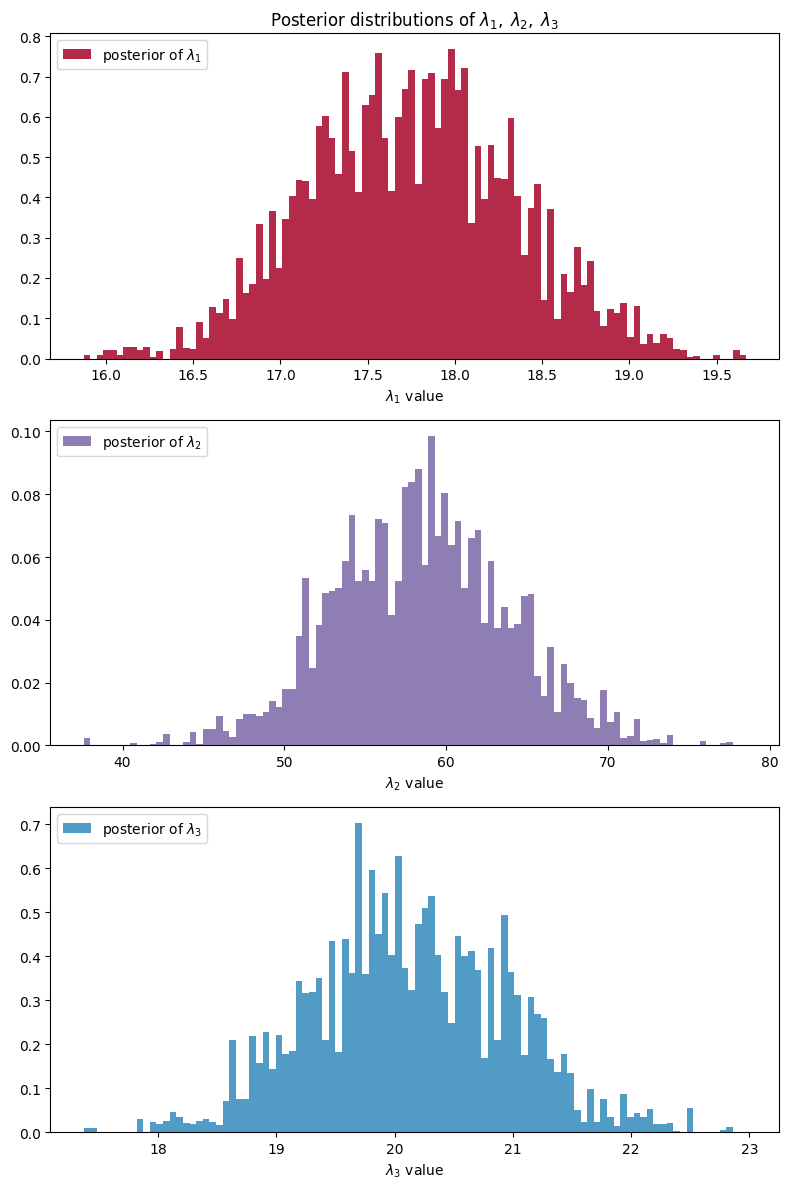

In [9]:
plt.figure(figsize=(8,12))

plt.subplot(311)
plt.hist(lambda_1_samples, histtype='stepfilled', bins=100, alpha=0.85,
         label="posterior of $\lambda_1$", color="#A60628", density=True)
plt.legend(loc="upper left")
plt.title(r"Posterior distributions of $\lambda_1,\;\lambda_2,\;\lambda_3$")
plt.xlabel("$\lambda_1$ value")

plt.subplot(312)
plt.hist(lambda_2_samples, histtype='stepfilled', bins=100, alpha=0.85,
         label="posterior of $\lambda_2$", color="#7A68A6", density=True)
plt.legend(loc="upper left")
plt.xlabel("$\lambda_2$ value")

plt.subplot(313)
plt.hist(lambda_3_samples, histtype='stepfilled', bins=100, alpha=0.85,
         label="posterior of $\lambda_3$", color="#348ABD", density=True)
plt.legend(loc="upper left")
plt.xlabel("$\lambda_3$ value")
plt.tight_layout();

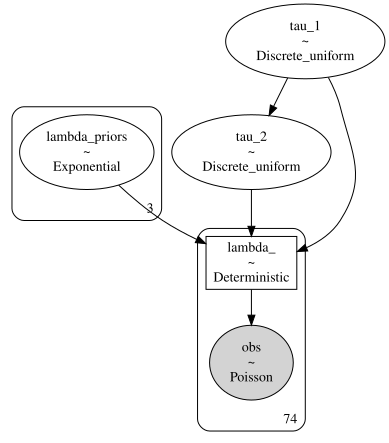

In [10]:
pm.model_to_graphviz(model)

### Lets look at the historgrams of tau1 and tau2 first

## Question:
### Do you think this data contains two or three arrival rates and why?

<div dir="rtl">

**תשובה:** לדעתי יש בנתונים שני קצבים ולא שלושה.

כשהרצתי את המודל עם שלושה קצבים, נקודת השינוי הראשונה יצאה ביום 45 והשנייה ביום 47. כלומר הקצב האמצעי נמשך רק יומיים. בימים האלה היו הרבה הודעות (70 ו-49), ולכן הקצב שלהם יצא גבוה מאוד, בערך 58 הודעות ביום.

לפני היומיים האלה הקצב הוא בערך 18 הודעות ביום, ואחריהם בערך 20. זה דומה למה שראינו בשיעור עם שני קצבים: שינוי אחד בסביבות יום 45.

לכן אני חושבת שהקצב השלישי לא מראה שינוי אמיתי בהרגלים, אלא רק יומיים חריגים. מודל עם יותר פרמטרים יכול לתפוס גם נקודות חריגות, אבל זה לא אומר שיש שם באמת תקופה חדשה.


</div>


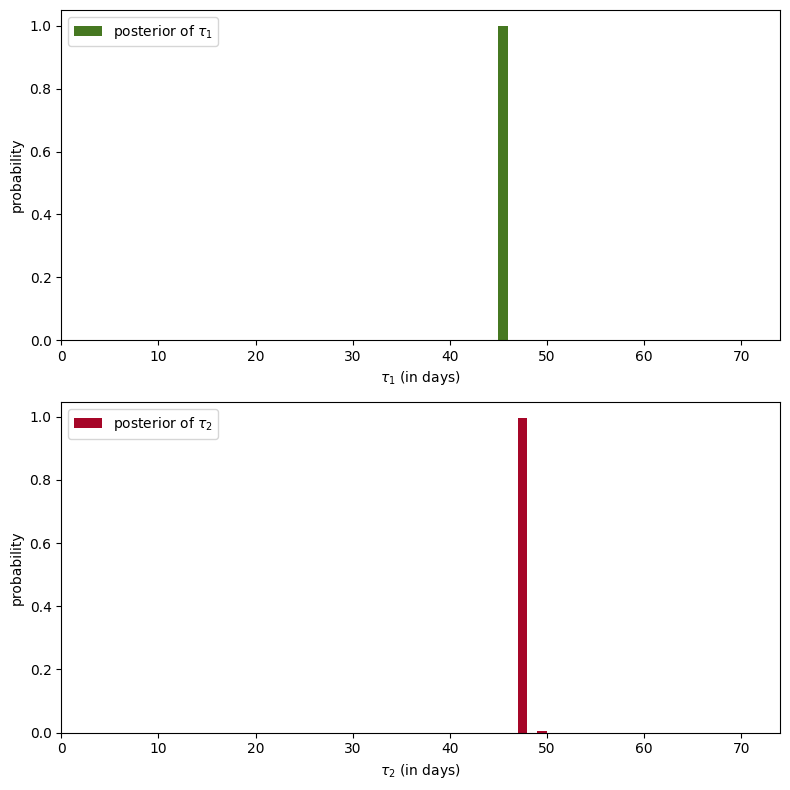

In [13]:
plt.figure(figsize=(8,8))

w1 = 1.0 / tau_1_samples.shape[0] * np.ones_like(tau_1_samples)
plt.subplot(211)
plt.hist(tau_1_samples, bins=np.arange(n_count_data + 1), alpha=1, weights=w1,
         label=r"posterior of $\tau_1$", color="#467821")
plt.legend(loc="upper left")
plt.xlim(0, n_count_data)
plt.xlabel(r"$\tau_1$ (in days)")
plt.ylabel("probability")

w2 = 1.0 / tau_2_samples.shape[0] * np.ones_like(tau_2_samples)
plt.subplot(212)
plt.hist(tau_2_samples, bins=np.arange(n_count_data + 1), alpha=1, weights=w2,
         label=r"posterior of $\tau_2$", color="#A60628")
plt.legend(loc="upper left")
plt.xlim(0, n_count_data)
plt.xlabel(r"$\tau_2$ (in days)")
plt.ylabel("probability")
plt.tight_layout();

In [14]:
print("lambda_1 mean:", lambda_1_samples.mean())
print("lambda_2 mean:", lambda_2_samples.mean())
print("lambda_3 mean:", lambda_3_samples.mean())
print("tau_1 most likely:", np.bincount(tau_1_samples).argmax())
print("tau_2 most likely:", np.bincount(tau_2_samples).argmax())

lambda_1 mean: 17.754793572918512
lambda_2 mean: 58.457972324545565
lambda_3 mean: 20.12950597237008
tau_1 most likely: 45
tau_2 most likely: 47


### Exercise 2: The following problem is very similar to the one above. We wish to check arrival rates of pateint into an emergency department of a hospital. Again, we wish to know the switching points. Suppose you know there can be only between 2 to 4 arrival rates. Which one of these options you think is best.  

<div dir="rtl">

**תשובה:** לדעתי המודל הכי מתאים הוא המודל עם שלושה קצבים.

במודל עם שלושה קצבים יצאו שלוש תקופות ברורות. עד יום 149 הגיע בערך מטופל אחד ביום, בין יום 149 ליום 201 הגיעו בערך 4 מטופלים ביום, ומיום 201 הגיעו בערך 7 מטופלים ביום. ההיסטוגרמות של שלושת הקצבים לא חופפות בכלל, וכל תקופה נמשכת לפחות 50 ימים, ולכן נראה שאלה שינויים אמיתיים. כלומר העלייה בהגעות לחדר המיון קרתה בשני שלבים ולא בבת אחת.

במודל עם שני קצבים יש רק שינוי אחד, ביום 149. המודל הזה מפספס את שלב הביניים, כי הוא מכניס את הימים 149 עד 201 לאותה תקופה עם קצב של בערך 6.6, למרות שבימים האלה הגיעו פחות מטופלים.

במודל עם ארבעה קצבים נקודת השינוי השנייה והשלישית יצאו שתיהן ביום 201, כלומר התקופה השלישית לא קיימת בפועל. בנוסף, ההיסטוגרמות של הקצב השני והשלישי חופפות ומפוזרות, והסימפלר התקשה להתכנס. לכן הקצב הרביעי לא מוסיף מידע על הנתונים.

לסיכום, שני קצבים זה מעט מדי ומפספס שלב אמיתי, וארבעה קצבים זה יותר מדי ומוסיף תקופה שלא קיימת. שלושה קצבים מתארים את הנתונים הכי טוב.

</div>



In [15]:

## load the data


colab = True
if colab:
  all_data = pkl.load(open("/arrival_data1.pkl", 'rb'))
else:
  all_data = pkl.load(open('../data/arrival_data1.pkl', 'rb'))


all_data

array([ 0,  3,  1,  1,  1,  1,  2,  1,  0,  0,  0,  0,  1,  0,  3,  1,  1,
        1,  1,  0,  1,  1,  0,  1,  2,  0,  0,  2,  1,  1,  0,  0,  0,  0,
        3,  2,  0,  1,  1,  1,  0,  0,  2,  2,  1,  2,  0,  0,  1,  2,  0,
        1,  1,  0,  2,  0,  0,  0,  0,  1,  0,  1,  0,  0,  0,  1,  0,  0,
        1,  1,  2,  0,  0,  1,  0,  0,  1,  1,  0,  1,  0,  1,  0,  2,  0,
        3,  2,  0,  1,  3,  1,  1,  0,  0,  1,  2,  0,  1,  0,  2,  1,  0,
        3,  0,  0,  0,  2,  1,  1,  1,  2,  1,  2,  2,  0,  2,  0,  1,  2,
        0,  0,  2,  2,  1,  1,  1,  1,  0,  1,  1,  1,  0,  2,  0,  1,  0,
        0,  1,  0,  1,  2,  0,  0,  3,  0,  3,  2,  0,  0,  3,  3,  4,  3,
        4,  1,  5,  2,  5,  5,  3,  2,  4,  4,  4,  6,  7,  1,  2,  5,  5,
        5,  3,  6,  2,  2,  5,  9,  6,  5,  3,  9,  4,  2,  5,  7,  2,  7,
        6,  3,  5,  4,  4,  5,  1,  4, 10,  3,  3,  3,  2,  4,  6,  9,  5,
       11,  8,  7,  3,  9,  7, 15,  5,  7,  5, 10,  5,  6,  4,  4,  4,  8,
        7, 11,  6,  7,  2

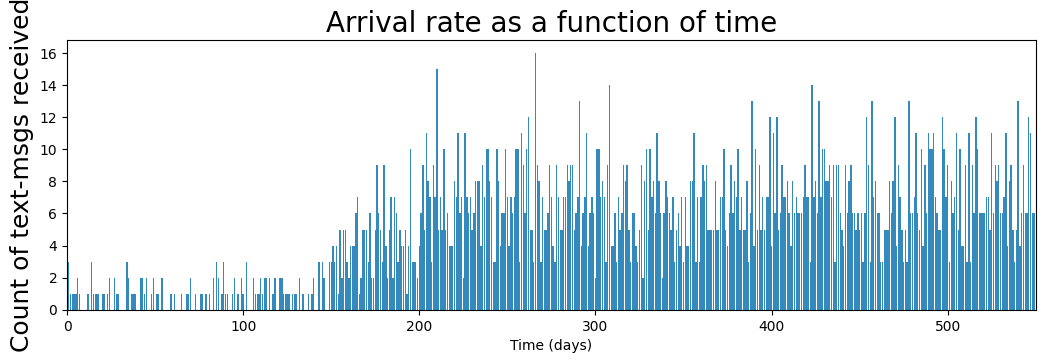

In [16]:
n_count_data = len(all_data)
plt.bar(np.arange(n_count_data), all_data, color="#348ABD")
plt.xlabel("Time (days)")
plt.ylabel("Count of text-msgs received", fontsize = 18)
plt.title("Arrival rate as a function of time", fontsize = 20)
plt.xlim(0, n_count_data);

## 2 arrival rates

In [17]:
n_data = len(all_data)
idx = np.arange(n_data)

with pm.Model() as model_2:
    alpha = 1.0/all_data.mean()
    lambdas = pm.Exponential("lambda_priors", alpha, shape=2)

    tau_1 = pm.DiscreteUniform("tau_1", lower=0, upper=n_data - 1)

    lambda_ = pm.Deterministic("lambda_", pm.math.switch(idx < tau_1, lambdas[0], lambdas[1]))

    observation = pm.Poisson("obs", lambda_, observed=all_data)

    step = pm.Metropolis()
    trace_2 = pm.sample(5000, tune=1000, step=step)

Output()

## 3 Arrival rates

lambda_1 mean: 0.8783399999173351
lambda_2 mean: 6.586502082501822
tau_1 most likely: 149


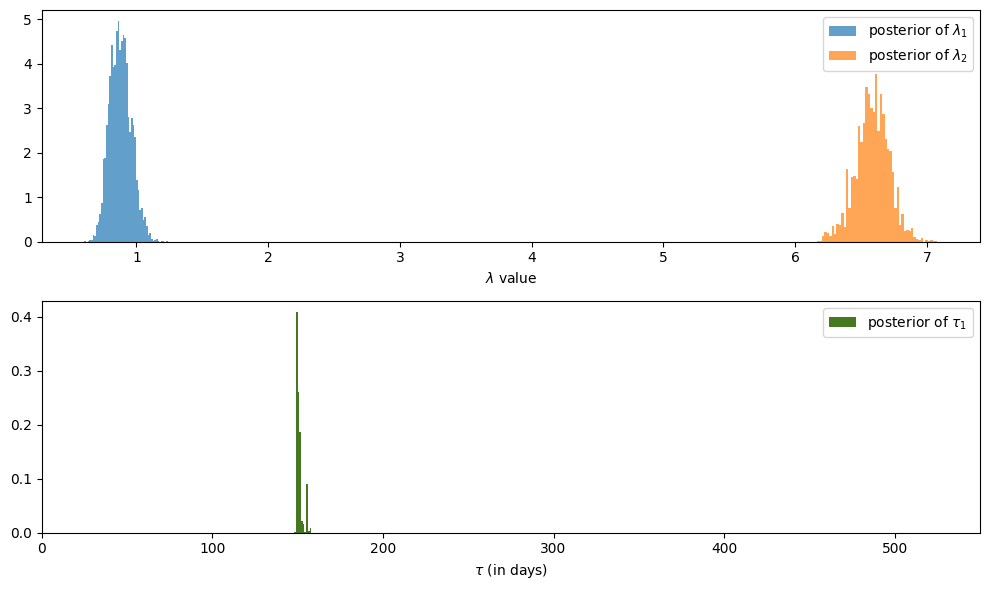

In [18]:
lambda_samples = trace_2.posterior['lambda_priors'].values
tau_1_samples = np.array(trace_2.posterior['tau_1']).flatten()

print("lambda_1 mean:", lambda_samples[:,:,0].mean())
print("lambda_2 mean:", lambda_samples[:,:,1].mean())
print("tau_1 most likely:", np.bincount(tau_1_samples).argmax())

plt.figure(figsize=(10,6))
plt.subplot(211)
for i in range(2):
    plt.hist(lambda_samples[:,:,i].flatten(), bins=50, alpha=0.7, density=True,
             label=f"posterior of $\\lambda_{i+1}$")
plt.legend()
plt.xlabel("$\\lambda$ value")

plt.subplot(212)
plt.hist(tau_1_samples, bins=np.arange(n_data + 1), density=True,
         label=r"posterior of $\tau_1$", color="#467821")
plt.legend()
plt.xlim(0, n_data)
plt.xlabel(r"$\tau$ (in days)")
plt.tight_layout();

lambda_1 mean: 0.8603744023770121
lambda_2 mean: 4.203337305597132
lambda_3 mean: 6.929312550350511
tau_1 most likely: 149
tau_2 most likely: 201


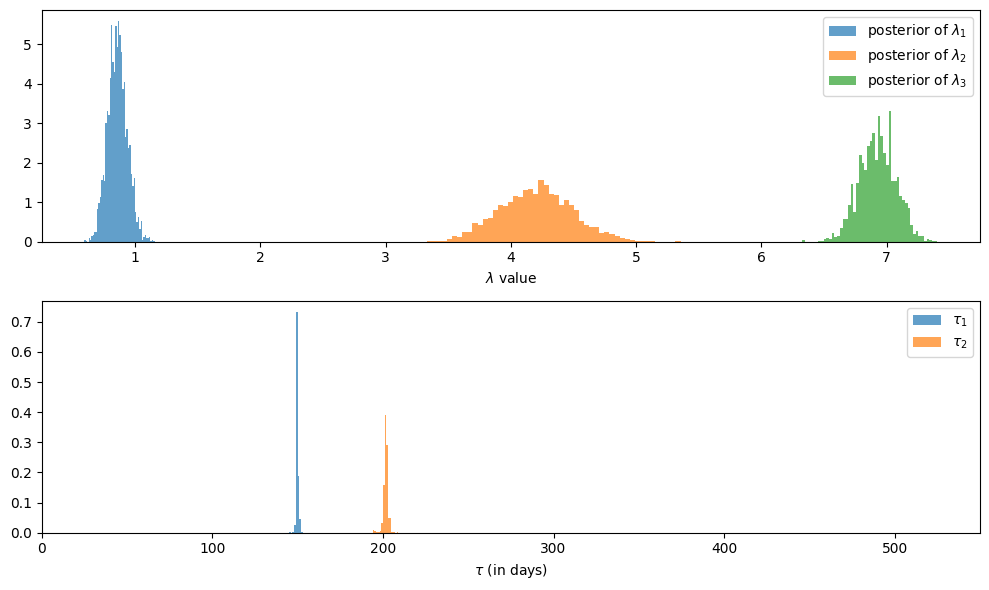

In [20]:
lambda_samples = trace_3.posterior['lambda_priors'].values
tau_1_samples = np.array(trace_3.posterior['tau_1']).flatten()
tau_2_samples = np.array(trace_3.posterior['tau_2']).flatten()

for i in range(3):
    print(f"lambda_{i+1} mean:", lambda_samples[:,:,i].mean())
print("tau_1 most likely:", np.bincount(tau_1_samples).argmax())
print("tau_2 most likely:", np.bincount(tau_2_samples).argmax())

plt.figure(figsize=(10,6))
plt.subplot(211)
for i in range(3):
    plt.hist(lambda_samples[:,:,i].flatten(), bins=50, alpha=0.7, density=True,
             label=f"posterior of $\\lambda_{i+1}$")
plt.legend()
plt.xlabel("$\\lambda$ value")

plt.subplot(212)
plt.hist(tau_1_samples, bins=np.arange(n_data + 1), density=True, alpha=0.7, label=r"$\tau_1$")
plt.hist(tau_2_samples, bins=np.arange(n_data + 1), density=True, alpha=0.7, label=r"$\tau_2$")
plt.legend()
plt.xlim(0, n_data)
plt.xlabel(r"$\tau$ (in days)")
plt.tight_layout();

## 4 arrival rates

In [21]:
with pm.Model() as model_4:
    alpha = 1.0/all_data.mean()
    lambdas = pm.Exponential("lambda_priors", alpha, shape=4)

    tau_1 = pm.DiscreteUniform("tau_1", lower=0, upper=n_data - 1)
    tau_2 = pm.DiscreteUniform("tau_2", lower=tau_1, upper=n_data - 1)
    tau_3 = pm.DiscreteUniform("tau_3", lower=tau_2, upper=n_data - 1)

    lambda_ = pm.Deterministic("lambda_", pm.math.switch(idx < tau_1, lambdas[0],
                                          pm.math.switch(idx < tau_2, lambdas[1],
                                          pm.math.switch(idx < tau_3, lambdas[2], lambdas[3]))))

    observation = pm.Poisson("obs", lambda_, observed=all_data)

    step = pm.Metropolis()
    trace_4 = pm.sample(5000, tune=1000, step=step)

Output()

ERROR:pymc.stats.convergence:The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


lambda_1 mean: 0.8569275040740806
lambda_2 mean: 3.4930425689366524
lambda_3 mean: 5.316573450195944
lambda_4 mean: 6.977162741416616
tau_1 most likely: 149
tau_2 most likely: 201
tau_3 most likely: 201


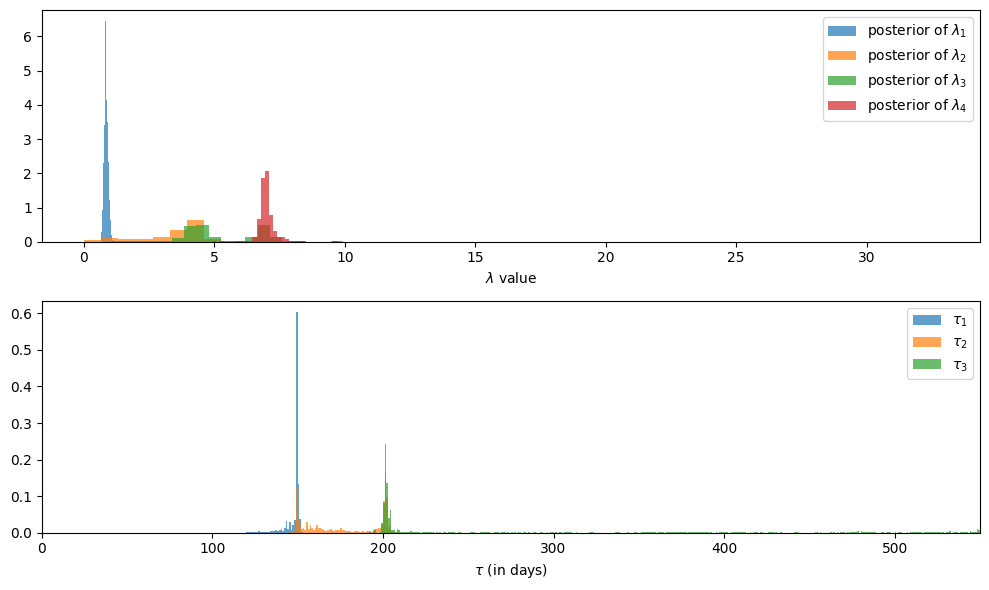

In [22]:
lambda_samples = trace_4.posterior['lambda_priors'].values
tau_samples = [np.array(trace_4.posterior[f'tau_{j}']).flatten() for j in (1,2,3)]

for i in range(4):
    print(f"lambda_{i+1} mean:", lambda_samples[:,:,i].mean())
for j in range(3):
    print(f"tau_{j+1} most likely:", np.bincount(tau_samples[j]).argmax())

plt.figure(figsize=(10,6))
plt.subplot(211)
for i in range(4):
    plt.hist(lambda_samples[:,:,i].flatten(), bins=50, alpha=0.7, density=True,
             label=f"posterior of $\\lambda_{i+1}$")
plt.legend()
plt.xlabel("$\\lambda$ value")

plt.subplot(212)
for j in range(3):
    plt.hist(tau_samples[j], bins=np.arange(n_data + 1), density=True, alpha=0.7,
             label=f"$\\tau_{j+1}$")
plt.legend()
plt.xlim(0, n_data)
plt.xlabel(r"$\tau$ (in days)")
plt.tight_layout();